# Велосипедные маршруты: табличный пайплайн

`prepare_city → edges/nodes → filter_edges → build_routes → score`

Решение — это фильтр, стоимость, модель поворотов и алгоритм поиска. Каждое поле можно задать двумя
способами, и они свободно смешиваются:

- **без кода** — имя из готового списка, JSON-словарь (`MY_PROFILE` в параметрах) или вызов `drop_values`;
- **кодом** — своя функция вместо любого поля (пример — профиль `code` в разделе «Стоимость»).

In [1]:
import json
from pathlib import Path
import sys

import networkx as nx
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from cycle_routing import (
    COMFORT_PRESETS, DEFAULT_COMFORT_CONFIG, SEARCH, TURNS, build_graph, build_routes, check_connectivity, cost_overview,
    drop_values, filter_edges, find_route, load_od_pairs,
    prepare_city, preparation_report, score,
)
from cycle_routing.visualization import (
    Panel, ROAD_CLASS_COLORS, SURFACE_CLASS_COLORS, cost_per_metre,
    mapped_popularity_map, popularity, road_classes, route_feature_grid, surface_classes,
)

D:\PythonProjects\CicleGpx\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Параметры

In [2]:
CITY = "konstanz"  # или "saint_petersburg"
REFRESH = False
CONNECTIVITY = "largest"  # "all", "restore" или "largest"
CACHE_DIR = PROJECT_ROOT / "notebooks" / "data" / "cities"
ROUTES_CACHE_DIR = PROJECT_ROOT / "outputs" / "routes_cache" / CITY
BASELINES = {
    "konstanz": PROJECT_ROOT / "outputs" / "konstanz_presets.csv",
    "saint_petersburg": PROJECT_ROOT / "outputs" / "spb_presets.csv",
}

# Профиль без кода: обычный JSON, его можно хранить в файле и читать json.load.
MY_PROFILE = {
    "label": "мой профиль",
    "description": "Настроен без кода: веса, повороты и алгоритм из списков",
    # Только изменённые веса поверх DEFAULT_COMFORT_CONFIG или имя пресета: "quiet", "smooth", ...
    "cost": {"highway": {"primary": 3.0, "secondary": 2.0, "cycleway": 0.4}, "surface": {"sett": 2.0}},
    # "none", "default", "min_turns" или поля TurnConfig в метрах
    "turns": {"left_penalty_m": 60, "u_turn_penalty_m": 200},
    # "dijkstra", "bellman_ford", "astar"
    "search": "dijkstra",
}
print("повороты:", list(TURNS), "\nпоиск:", list(SEARCH))
print("веса:", json.dumps(DEFAULT_COMFORT_CONFIG, ensure_ascii=False)[:300], "...")

повороты: ['none', 'default', 'min_turns'] 
поиск: ['dijkstra', 'bellman_ford', 'astar']
веса: {"highway": {"cycleway": 0.55, "living_street": 0.8, "path": 0.85, "residential": 1.0, "pedestrian": 1.1, "service": 1.1, "track": 1.2, "unclassified": 1.15, "footway": 1.3, "tertiary": 1.25, "secondary": 1.55, "primary": 2.1, "trunk": 3.5, "motorway": 8.0, "steps": 6.0}, "surface": {"asphalt": 1.0, ...


## Данные

`edges` — плоская таблица OSM; в ней сохраняются и дороги без измерений поездок.
В отдельной таблице популярности `trips=NaN` означает отсутствие сопоставленного наблюдения,
`trips=0` — подтверждённый ноль. `has_observation` явно отмечает наличие измерения.
В ML используется только известная популярность train. Географическая маска покрытия
задаёт область анализа, но не превращает соседние неизмеренные дороги в нулевые примеры.


In [3]:
edges, nodes = prepare_city(CITY, cache_dir=CACHE_DIR, refresh=REFRESH)
display(pd.Series(preparation_report(CITY, cache_dir=CACHE_DIR), name="значение"))
display(edges.head())

tag_columns = ["highway", "surface", "smoothness", "cycleway", "bicycle", "lit", "service", "access"]
filled = edges[tag_columns].notna().mean().sort_values(ascending=False).rename("доля заполненных")
display(filled.to_frame())
display(edges["highway"].value_counts(dropna=False).head(15).rename("рёбер").to_frame())
assert not {"trips", "stad_trips", "gpx_tracks", "popularity"} & set(edges.columns)

edges                   169016.000000
nodes                    64934.000000
reference_edges         156340.000000
od_pairs                    20.000000
observed_edges           27891.000000
positive_edges           27133.000000
zero_edges                 758.000000
unknown_edges           141125.000000
stad_match_rate              0.970490
p95_match_distance_m         4.578409
osm_edge_match_rate          0.178400
Name: значение, dtype: float64

,u,v,key,length_m,highway,surface,smoothness,cycleway,bicycle,lit,service,access,maxspeed,lanes,width,oneway,geometry
0,2104826,300373377,0,15.347149,trunk,asphalt,excellent,NaN,NaN,NaN,NaN,NaN,120.0,2.0,8.0,False,"LINESTRING (510904.57 5293356.095, 510918.684 ..."
1,2104826,2952488357,0,103.927993,trunk,asphalt,excellent,NaN,NaN,NaN,NaN,NaN,120.0,3.0,11.2,False,"LINESTRING (510904.57 5293356.095, 510865.913 ..."
2,2104826,2104830,0,122.318579,trunk_link,asphalt,excellent,NaN,NaN,no,NaN,NaN,50.0,1.0,5.3,True,"LINESTRING (510904.57 5293356.095, 510909.899 ..."
3,2104830,300373373,0,93.454429,trunk_link,asphalt,excellent,NaN,NaN,NaN,NaN,NaN,70.0,1.0,5.3,True,"LINESTRING (510967.478 5293262.254, 510959.563..."
4,2104830,2104833,0,79.572918,trunk_link,asphalt,NaN,NaN,NaN,NaN,NaN,NaN,50.0,2.0,10.0,False,"LINESTRING (510967.478 5293262.254, 510979.831..."


,доля заполненных
highway,1.000000
surface,0.758496
lit,0.344595
smoothness,0.309503
cycleway,0.262023
service,0.129307
bicycle,0.104434
access,0.042191


,рёбер
highway,
service,36736
residential,30819
track,29205
footway,24970
path,16566
tertiary,7153
secondary,4877
unclassified,4794
primary,2070


## Карта сопоставленной популярности

Карта строится по исходным `edges`, до фильтра маршрутизации. По умолчанию показаны все известные
измерения, включая настоящий ноль. Цвет отражает количество поездок в логарифмической шкале.
В popup есть `has_observation`. Для отображения также неизвестных дорог передайте
`only_observed=False`: они будут серыми пунктирными линиями с подписью «нет данных».


In [4]:
mapped_popularity_map(edges, CITY, cache_dir=CACHE_DIR)

## Фильтр и связность

Что убрать из сети, решаете вы. `drop_values(edges, колонка=[значения])` возвращает маску, в которой
рёбра с этими значениями отмечены `False`; маски объединяются через `&` и `|`. Подойдёт и любая своя
pandas-маска. Значения тегов видны в таблицах раздела «Данные».

`CONNECTIVITY="largest"` оставляет одну компоненту, `"restore"` возвращает минимальный набор реальных
OSM-перемычек, `"all"` сохраняет все разрозненные части.

In [5]:
keep = drop_values(edges)  # пока ничего не убираем: drop_values(edges, колонка=["значение", ...])
# Кодом: keep = drop_values(edges, колонка=["значение"]) & (edges["колонка"] != "значение")

filtered = filter_edges(
    edges, keep,
    connect_components=CONNECTIVITY == "restore",
    keep_largest=CONNECTIVITY == "largest",
)
filtered = check_connectivity(filtered)
display(filtered.head())

Маска убрала 0 рёбер; после связности осталось 168 518 из 169 016 (убрано 19.7 км).


Связных частей: 1. Вне крупнейшей 0 рёбер (0.0 км).


,u,v,key,length_m,highway,surface,smoothness,cycleway,bicycle,lit,service,access,maxspeed,lanes,width,oneway,geometry
0,2104826,300373377,0,15.347149,trunk,asphalt,excellent,NaN,NaN,NaN,NaN,NaN,120.0,2.0,8.0,False,"LINESTRING (510904.57 5293356.095, 510918.684 ..."
1,2104826,2952488357,0,103.927993,trunk,asphalt,excellent,NaN,NaN,NaN,NaN,NaN,120.0,3.0,11.2,False,"LINESTRING (510904.57 5293356.095, 510865.913 ..."
2,2104826,2104830,0,122.318579,trunk_link,asphalt,excellent,NaN,NaN,no,NaN,NaN,50.0,1.0,5.3,True,"LINESTRING (510904.57 5293356.095, 510909.899 ..."
3,2104830,300373373,0,93.454429,trunk_link,asphalt,excellent,NaN,NaN,NaN,NaN,NaN,70.0,1.0,5.3,True,"LINESTRING (510967.478 5293262.254, 510959.563..."
4,2104830,2104833,0,79.572918,trunk_link,asphalt,NaN,NaN,NaN,NaN,NaN,NaN,50.0,2.0,10.0,False,"LINESTRING (510967.478 5293262.254, 510979.831..."


## Стоимость, повороты и поиск

`mine` — профиль из параметров, без кода. `code` — то же самое, но каждое поле заменено функцией:
- `cost(edges) -> Series` — стоимость каждого ребра в эквивалентных метрах;
- `turns(graph, incoming, outgoing) -> метры` — штраф поворота;
- `search` — функция networkx как есть (`nx.astar_path`, `nx.bellman_ford_path`) или своя с сигнатурой
  `search(graph, source, target, weight="cost") -> [узлы]`.

In [6]:
def my_comfort(edges):
    factor = pd.Series(1.0, index=edges.index)
    factor += 1.5 * edges["highway"].isin(["primary", "secondary"])
    factor += 0.5 * edges["surface"].isin(["sett", "cobblestone"])
    return edges["length_m"] * factor

def junction_turns(graph, incoming, outgoing):
    # Штраф только на настоящем перекрёстке, изгиб улицы бесплатный.
    return 40.0 if graph.out_degree(outgoing[0]) > 2 else 0.0

MY_PRESETS = {
    **COMFORT_PRESETS,
    "mine": MY_PROFILE,
    "code": {
        "label": "профиль кодом",
        "description": "Свои функции стоимости и поворотов, поиск из networkx",
        "cost": my_comfort,
        "turns": junction_turns,
        "search": nx.astar_path,
    },
}

display(cost_overview(MY_PRESETS))

,primary,primary + велополоса,secondary,жилая улица,велодорожка,тротуар,брусчатка,грунтовка,"поворот налево, м"
сбалансированный,2.772,1.502,1.55,1.0,0.55,1.456,1.45,1.62,30.0
быстрый,1.265,1.138,1.05,1.0,0.85,1.344,1.20,1.56,30.0
минимум поворотов,1.265,1.138,1.05,1.0,0.85,1.344,1.20,1.56,300.0
по проспектам,1.320,0.550,1.00,1.0,0.55,1.456,1.45,1.62,30.0
спокойный,14.175,7.875,3.20,1.0,0.50,1.232,1.45,1.62,30.0
велоинфраструктура,2.772,0.808,1.55,1.0,0.30,2.240,1.45,2.16,30.0
гладкий асфальт,2.112,1.144,1.30,1.0,0.55,2.560,2.80,6.60,30.0
парки и грунт,3.960,2.145,2.20,1.0,0.60,0.900,1.45,0.65,30.0
мой профиль,3.960,2.145,2.00,1.0,0.40,1.456,2.00,1.62,60.0
профиль кодом,2.500,2.500,2.50,1.0,1.00,1.000,1.50,1.00,NaN


## Один маршрут и сменные точки

In [7]:
pairs = load_od_pairs(CITY, cache_dir=CACHE_DIR)
preset = MY_PRESETS["mine"]
graph = build_graph(filtered, nodes, cost=preset["cost"])

example = first = None
for _, pair in pairs.iterrows():
    route = find_route(
        graph, int(pair.origin), int(pair.destination),
        search=preset["search"], turns=preset["turns"],
    )
    if route is not None:
        first, example = pair, route
        break

if example is None:
    raise RuntimeError("Ни одна OD-пара не прокладывается: проверьте CONNECTIVITY и фильтр")

display(pd.Series({key: value for key, value in example.items() if key != "geometry"}))

edge_route        [(1863431495, 296211870, 0), (296211870, 98883...
route_length_m                                          8376.698547
turns                                                            15
dtype: object

## Все пресеты и оценка

`build_routes` всегда добавляет физически кратчайший baseline. Каждый профиль проходит через тот же
`build_graph` и `find_route`, что и пользовательская функция. `score` сам читает отдельный кеш
популярности. Метрика `сумма поездок по рёбрам` складывает `trips` всех пройденных рёбер;
повторное прохождение ребра в разных OD-маршрутах считается повторно.

In [8]:
routes = build_routes(
    filtered, nodes, pairs, MY_PRESETS, cache_dir=ROUTES_CACHE_DIR,
)
model_order = ["shortest", *MY_PRESETS]
route_counts = routes["algorithm"].value_counts().reindex(model_order, fill_value=0)
assert route_counts["mine"] > 0, "Профиль mine не построил ни одного маршрута"
display(route_counts.rename("построено маршрутов").to_frame())

metrics = score(routes, CITY, cache_dir=CACHE_DIR)
display(metrics.reindex(model_order))

Routes by preset:   0%|          | 0/11 [00:00<?, ?it/s]

Routes by preset:  18%|█▊        | 2/11 [00:00<00:01,  6.60it/s]

Routes by preset:  27%|██▋       | 3/11 [00:00<00:01,  5.06it/s]

Routes by preset:  36%|███▋      | 4/11 [00:00<00:01,  4.35it/s]

Routes by preset:  45%|████▌     | 5/11 [00:01<00:01,  4.19it/s]

...

Routes by preset:  82%|████████▏ | 9/11 [00:02<00:00,  3.65it/s]

Routes by preset:  91%|█████████ | 10/11 [00:02<00:00,  3.62it/s]

Routes by preset: 100%|██████████| 11/11 [00:02<00:00,  4.28it/s]

,построено маршрутов
algorithm,
shortest,20
balanced,20
fast,20
min_turns,20
avenues,20
quiet,20
bike_infra,20
smooth,20
nature,20


,"объезд, %",поворотов,поездок × кратчайший,"популярные улицы, %",популярнее кратчайшего,связь с популярностью,"покрытие измерениями, %",сумма поездок по рёбрам,"лестницы, рёбер","автомагистрали, рёбер","закрытый доступ, рёбер","bicycle=no/dismount, рёбер","стройки, платформы, лифты, рёбер"
shortest,0.000000,12.5,1.000000,55.075113,NaN,0.122614,95.120094,329430.329306,5,1,3,15,0
balanced,6.993577,10.0,4.107285,87.357524,18/20,0.314570,98.586805,893970.438254,0,0,4,0,0
fast,3.023809,9.5,2.111516,84.470450,18/20,0.252084,98.498145,685083.894502,0,0,4,0,0
min_turns,7.347851,6.0,1.782046,77.407005,16/20,0.221951,98.422678,594008.298241,2,0,0,0,0
avenues,4.704565,9.5,2.422213,85.489748,19/20,0.258286,96.942340,620467.311771,0,0,4,0,0
quiet,9.741232,12.0,2.986434,82.730123,18/20,0.283282,98.386467,764937.347335,0,0,0,1,0
bike_infra,7.901744,11.5,2.656371,88.725684,18/20,0.280021,98.058351,730410.124576,0,0,4,0,0
smooth,8.896178,11.0,2.025682,78.683930,16/20,0.237965,97.475194,676774.965454,0,0,4,0,0
nature,8.187769,10.5,2.424775,86.142206,18/20,0.256704,96.717431,679688.563733,0,0,4,1,0
mine,7.400903,10.0,3.298422,86.745220,18/20,0.295596,98.561519,831183.982859,0,0,4,0,0


## Сравнение с историческим расчётом

CSV ниже сохранён до исправления пропусков: часть отсутствующих измерений раньше считалась нулём.
Расхождения с ним ожидаемы и не являются проверкой регрессии. Пересчитанные показатели сохраняются
в `outputs/ml_popularity/` и `outputs/od_topology/`; корректность различения NaN/0 проверяется тестами.


In [9]:
labels = {"shortest": "кратчайший", **{name: preset["label"] for name, preset in MY_PRESETS.items()}}
actual = metrics.rename(index=labels)
reference = pd.read_csv(BASELINES[CITY], index_col=0)
common_rows = actual.index.intersection(reference.index)
common_columns = actual.select_dtypes("number").columns.intersection(reference.select_dtypes("number").columns)
delta = (actual.loc[common_rows, common_columns] - reference.loc[common_rows, common_columns]).abs()
display(delta.max().rename("максимальное |расхождение|").to_frame())
print("Исторический CSV рассчитан до исправления NaN/0; различия ожидаемы. Актуальные результаты — в ML- и OD-разделах ниже.")


,максимальное |расхождение|
"объезд, %",0.967835
поворотов,0.500000
поездок × кратчайший,1.053169
"популярные улицы, %",8.460621
связь с популярностью,0.031250


Исторический CSV рассчитан до исправления NaN/0; различия ожидаемы. Актуальные результаты — в ML- и OD-разделах ниже.


## Карта первого маршрута

In [10]:
first_routes = routes[routes["od_id"] == first.od_id]
panels = [
    Panel("Тип дороги", road_classes, categories=ROAD_CLASS_COLORS),
    Panel("Покрытие", surface_classes, categories=SURFACE_CLASS_COLORS),
    Panel("Стоимость balanced на метр", cost_per_metre(COMFORT_PRESETS["balanced"]["cost"])),
    Panel("Наблюдаемая популярность", popularity(CITY, cache_dir=CACHE_DIR), log=True, higher_is_better=True),
]
route_feature_grid(
    filtered, nodes, first_routes, panels,
    (first.start_lat, first.start_lon), (first.end_lat, first.end_lon),
    start_label=first.start_label, end_label=first.end_label,
)

## ML: популярность улиц и влияние настроек

Цель — по OSM-признакам выбирать улицы, которыми чаще пользуются велосипедисты. Наблюдения Констанца
содержат потоки по участкам, поэтому популярность маршрута измеряем вдоль его улиц.

Градиентный бустинг предсказывает `log(1 + trips)` по типу дороги, покрытию, ровности, освещению,
велоинфраструктуре, доступу, скорости, полосам и ширине. Координаты, ID и наблюдаемые поездки
не входят в признаки. Только сопоставленные значения, включая явный ноль, используются как метки;
все NaN исключены из обучения и оценки.

Пространственные блоки по 1 км делятся на **train / validation / test** примерно 60/20/20.
Оба направления одной улицы находятся в одной части. Географическое разбиение сохранено прежним;
в каждой части используются только рёбра с известным количеством поездок. Обучаемся на train, выбираем силу ML на validation,
после выбора открываем test. Это пространственная проверка, а не проверка на новых поездках во времени.

Исходные ячейки выше остаются самостоятельным примером. Этот эксперимент использует общую допустимую
велосипедную сеть и одинаковые OD-пары для всех настроек.


In [11]:
import numpy as np
import matplotlib.pyplot as plt

from cycle_routing import edge_trips, is_rideable, observed_area
from cycle_routing.evaluation import route_popularity_metrics, weighted_corr
from cycle_routing.learning import (
    FEATURE_COLUMNS, fit_popularity_model, popularity_cost, spatial_partition,
)

ML_CITY = "konstanz"
ML_SEED = 42
ML_CELL_M = 1_000
ML_MAX_ITER = 120
ML_MAX_LEAF_NODES = 15
ML_STRENGTHS = [0.0, 0.25, 0.5, 1.0]
CYCLEWAY_WEIGHTS = [0.25, 1.0, 4.0]
MAX_DETOUR_PCT = 20.0
MIN_EVAL_COVERAGE_PCT = 10.0
RUN_SPB_CHECK = False  # True: отдельный прогон СПб, при отсутствии актуального кеша скачает OSM
ML_OUTPUT_DIR = PROJECT_ROOT / "outputs" / "ml_popularity"
ML_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


In [12]:
ml_edges, ml_nodes = prepare_city(ML_CITY, cache_dir=CACHE_DIR)
ml_network = filter_edges(ml_edges, is_rideable, keep_largest=True)
ml_trips = edge_trips(ml_network, ML_CITY, cache_dir=CACHE_DIR)
ml_surveyed = observed_area(ml_network, ML_CITY, cache_dir=CACHE_DIR)
ml_known = ml_trips.notna()
ml_partition = spatial_partition(
    ml_network, ml_surveyed, cell_m=ML_CELL_M, random_state=ML_SEED,
)
split_report = pd.DataFrame({
    "рёбер": ml_partition.value_counts(),
    "измерено": ml_known.groupby(ml_partition).sum(),
    "явный ноль": ml_trips.eq(0).groupby(ml_partition).sum(),
    "без измерения": (~ml_known).groupby(ml_partition).sum(),
    "длина, км": ml_network.length_m.groupby(ml_partition).sum() / 1000,
}).reindex(["train", "validation", "test", "outside"])
display(split_report)
print("Признаки модели:", ", ".join(FEATURE_COLUMNS))
assert not {"trips", "popularity", "u", "v", "key", "geometry", "length_m"} & set(FEATURE_COLUMNS)


Маска убрала 12 676 рёбер; после связности осталось 153 310 из 169 016 (убрано 996.0 км).


,рёбер,измерено,явный ноль,без измерения,"длина, км"
partition,,,,,
train,29334,17283,433,12051,1950.854822
validation,9902,5798,126,4104,742.518139
test,10715,4502,135,6213,694.723288
outside,103359,0,0,103359,9709.641706


Признаки модели: highway, surface, smoothness, cycleway, bicycle, lit, service, access, maxspeed, lanes, width, oneway


### Прогноз популярности по характеристикам улиц

Модель видит только строки train. Константный прогноз — среднее `log(1 + trips)` на train.
Показываем MAE прогноза в логарифмической шкале и корреляцию с наблюдениями на validation,
взвешенные по длине. Значение test пока не используем. Параметры бустинга заданы выше.


In [13]:
ml_train = ml_partition.eq("train") & ml_known
ml_model = fit_popularity_model(
    ml_network[ml_train], ml_trips[ml_train], random_state=ML_SEED,
    max_iter=ML_MAX_ITER, max_leaf_nodes=ML_MAX_LEAF_NODES,
)
ml_prediction = ml_model.predict_log_trips(ml_network)

def prediction_report(partition_name):
    selected = ml_partition.eq(partition_name) & ml_known
    target = np.log1p(ml_trips[selected].to_numpy())
    weights = ml_network.loc[selected, "length_m"].to_numpy()
    rows = []
    for name, predicted in {
        "среднее train": np.full(len(target), ml_model.reference_log),
        "градиентный бустинг": ml_prediction[selected].to_numpy(),
    }.items():
        correlation = weighted_corr(predicted, target, weights) if np.ptp(predicted) > 0 else np.nan
        rows.append({
            "модель": name,
            "MAE log(1+trips)": np.average(np.abs(target - predicted), weights=weights),
            "корреляция": correlation,
        })
    return pd.DataFrame(rows).set_index("модель")

ml_validation_quality = prediction_report("validation")
display(ml_validation_quality)


,MAE log(1+trips),корреляция
модель,,
среднее train,1.473690,NaN
градиентный бустинг,0.997348,0.685009


### Меняют ли настройки маршруты и их популярность?

Сравниваем два независимых параметра:

- **Сила ML α**: `cost = length × exp(-α × clip(прогноз − среднее train, -3, 3))`.
  При α=0 получается кратчайший путь. Чем больше α, тем сильнее предпочтение предсказанно популярных улиц.
- **Вес highway=cycleway**: меняем один коэффициент готовой функции стоимости, оставляя остальные прежними.

У всех вариантов один фильтр, одни пары A–B, Дейкстра и отсутствие штрафов поворотов.
Поэтому изменение пути связано с весами. В граф передаются только стоимости, без наблюдаемой популярности.

Оценка — среднее `log(1 + trips)`, взвешенное по длине участков нужной части данных.
`(1+поездки) × кратчайший` — экспонента медианного выигрыша этого показателя по OD-парам.
Это отношение геометрических средних `1 + trips`, а не количество полных поездок между A и B.
Показываем покрытие: вне validation/test улицы не считаются улицами с нулём поездок.
Для сравнения берём общие OD, где у всех вариантов покрыто хотя бы 10% длины.
Больший коэффициент не обязан улучшать популярность: таблица показывает фактический эффект.


In [14]:
experiment_profiles = {}
experiment_parameters = {}
for strength in ML_STRENGTHS:
    name = f"ml_{strength:g}"
    experiment_parameters[name] = {"семейство": "ML", "параметр": strength}
    experiment_profiles[name] = {
        "label": f"ML α={strength:g}", "turns": None, "search": "dijkstra",
        "cost": popularity_cost(ml_network, ml_prediction, strength=strength,
                                reference_log=ml_model.reference_log),
    }
for weight in CYCLEWAY_WEIGHTS:
    name = f"cycleway_{weight:g}"
    experiment_parameters[name] = {"семейство": "вес велодорожки", "параметр": weight}
    experiment_profiles[name] = {
        "label": f"вес велодорожки={weight:g}", "turns": None, "search": "dijkstra",
        "cost": {"highway": {"cycleway": weight}},
    }

experiment_pairs = load_od_pairs(ML_CITY, cache_dir=CACHE_DIR)
experiment_routes = build_routes(
    ml_network, ml_nodes, experiment_pairs, experiment_profiles,
    cache_dir=ML_OUTPUT_DIR / "routes_cache",
)
display(experiment_routes.algorithm.value_counts().rename("маршрутов").to_frame())


Routes by preset:   0%|          | 0/8 [00:00<?, ?it/s]

Routes by preset:  38%|███▊      | 3/8 [00:03<00:05,  1.05s/it]

Routes by preset:  50%|█████     | 4/8 [00:05<00:05,  1.41s/it]

Routes by preset:  62%|██████▎   | 5/8 [00:09<00:06,  2.16s/it]

Routes by preset:  75%|███████▌  | 6/8 [00:09<00:03,  1.58s/it]

Routes by preset:  88%|████████▊ | 7/8 [00:09<00:01,  1.17s/it]

Routes by preset: 100%|██████████| 8/8 [00:09<00:00,  1.11it/s]

Routes by preset: 100%|██████████| 8/8 [00:09<00:00,  1.24s/it]

,маршрутов
algorithm,
shortest,20
ml_0,20
ml_0.25,20
ml_0.5,20
ml_1,20
cycleway_0.25,20
cycleway_1,20
cycleway_4,20


In [15]:
def summarize_popularity(candidate_routes, network, trips, evaluation_mask):
    details = route_popularity_metrics(candidate_routes, network, trips, mask=evaluation_mask)
    baseline = details[details.algorithm.eq("shortest")].set_index("od_id")
    details = details.join(
        baseline[["route_length_m", "popularity_log_mean", "coverage_pct"]].add_prefix("baseline_"),
        on="od_id", validate="many_to_one",
    )
    details["gain"] = details.popularity_log_mean - details.baseline_popularity_log_mean
    details["detour"] = 100 * (details.route_length_m / details.baseline_route_length_m - 1)
    enough = details.coverage_pct.ge(MIN_EVAL_COVERAGE_PCT) & details.gain.notna()
    common_od = details.assign(enough=enough).groupby("od_id").agg(
        all_covered=("enough", "all"), models=("algorithm", "nunique"),
    )
    common_od = common_od.index[common_od.all_covered & common_od.models.eq(candidate_routes.algorithm.nunique())]
    paths = candidate_routes.set_index(["algorithm", "od_id"]).edge_route.map(
        lambda path: tuple(tuple(edge) for edge in path)
    )
    base_paths = paths.loc["shortest"]
    rows = []
    for algorithm, frame in details.groupby("algorithm", sort=False):
        paired = frame[frame.od_id.isin(common_od)]
        model_paths = paths.loc[algorithm]
        changed = sum(path != base_paths.loc[od_id] for od_id, path in model_paths.items())
        rows.append({
            "algorithm": algorithm, "маршрутов": len(frame), "изменилось": changed,
            "OD для оценки": len(paired),
            "средняя log-популярность": paired.popularity_log_mean.median(),
            "(1+поездки) × кратчайший": np.exp(paired.gain.median()),
            "выигрыш log-популярности": paired.gain.median(),
            "объезд, %": frame.detour.median(),
            "покрытие, %": paired.coverage_pct.median(),
        })
    return pd.DataFrame(rows).set_index("algorithm"), details

validation_table, validation_details = summarize_popularity(
    experiment_routes, ml_network, ml_trips, ml_partition.eq("validation") & ml_known,
)
validation_table = validation_table.join(pd.DataFrame.from_dict(experiment_parameters, orient="index"))
validation_table["изменилось от предыдущей настройки"] = 0
for family in ["ML", "вес велодорожки"]:
    previous_paths = None
    for name in validation_table[validation_table["семейство"].eq(family)].sort_values("параметр").index:
        current_paths = experiment_routes[experiment_routes.algorithm.eq(name)].set_index("od_id").edge_route
        current_paths = current_paths.map(lambda path: tuple(tuple(edge) for edge in path))
        if previous_paths is not None:
            validation_table.loc[name, "изменилось от предыдущей настройки"] = sum(
                path != previous_paths.loc[od_id] for od_id, path in current_paths.items()
            )
        previous_paths = current_paths
display(validation_table.round(3))

# Проверяем и изменение пути, и изменение наблюдаемой популярности, а не только чисел cost.
assert validation_table["OD для оценки"].min() > 0, "Недостаточно общих OD в validation"
assert validation_table.loc["ml_0", "изменилось"] == 0, "α=0 должен воспроизводить кратчайший путь"
ml_effect = validation_table.loc[validation_table["семейство"].eq("ML")]
cycle_effect = validation_table.loc[validation_table["семейство"].eq("вес велодорожки")]
assert ml_effect["изменилось"].max() > 0, "Сила ML пока не меняет маршруты"
assert ml_effect["выигрыш log-популярности"].max() - ml_effect["выигрыш log-популярности"].min() > 1e-6
cycle_paths = experiment_routes[experiment_routes.algorithm.str.startswith("cycleway_")]
cycle_signatures = cycle_paths.groupby("algorithm").edge_route.apply(
    lambda paths: tuple(tuple(tuple(edge) for edge in path) for path in paths)
)
assert len(set(cycle_signatures)) > 1, "Вес велодорожки пока не меняет маршруты"
assert cycle_effect["выигрыш log-популярности"].max() - cycle_effect["выигрыш log-популярности"].min() > 1e-6
print("Проверено: сила ML и вес велодорожки меняют пути и наблюдаемую популярность.")
validation_table.to_csv(ML_OUTPUT_DIR / "validation_sensitivity.csv")


,маршрутов,изменилось,OD для оценки,средняя log-популярность,(1+поездки) × кратчайший,выигрыш log-популярности,"объезд, %","покрытие, %",семейство,параметр,изменилось от предыдущей настройки
algorithm,,,,,,,,,,,
shortest,20,0,12,4.887,1.000,0.000,0.000,34.315,NaN,NaN,0
ml_0,20,0,12,4.887,1.000,0.000,0.000,34.315,ML,0.00,0
ml_0.25,20,20,12,5.602,3.868,1.353,6.105,25.384,ML,0.25,20
ml_0.5,20,20,12,5.778,5.921,1.779,11.857,25.881,ML,0.50,16
ml_1,20,20,12,5.896,7.285,1.986,21.075,23.998,ML,1.00,14
cycleway_0.25,20,20,12,5.691,2.792,1.027,4.666,22.312,вес велодорожки,0.25,0
cycleway_1,20,20,12,5.691,2.792,1.027,4.658,23.857,вес велодорожки,1.00,7
cycleway_4,20,20,12,5.536,2.381,0.867,3.740,22.461,вес велодорожки,4.00,10


Проверено: сила ML и вес велодорожки меняют пути и наблюдаемую популярность.


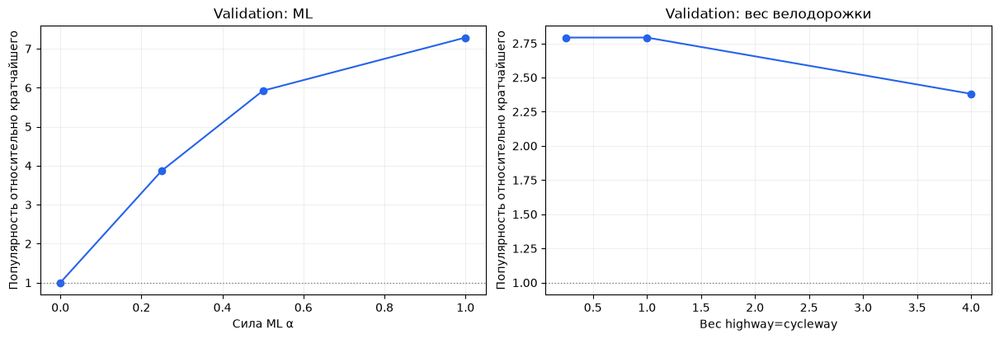

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for axis, family in zip(axes, ["ML", "вес велодорожки"]):
    subset = validation_table[validation_table["семейство"].eq(family)].sort_values("параметр")
    axis.plot(subset["параметр"], subset["(1+поездки) × кратчайший"], "o-", color="#2563eb")
    axis.axhline(1, color="grey", linewidth=1, linestyle=":")
    axis.set(xlabel="Сила ML α" if family == "ML" else "Вес highway=cycleway",
             ylabel="Популярность относительно кратчайшего", title=f"Validation: {family}")
    axis.grid(alpha=0.2)
fig.savefig(ML_OUTPUT_DIR / "sensitivity.png", dpi=160)
plt.show()


### Итоговая проверка на test

Силу ML выбираем только по validation: наибольший выигрыш популярности среди вариантов с медианным
объездом не больше заданного лимита. α=0 также участвует: если ML не помогает, результатом станет
кратчайший путь. Затем сравниваем только выбранный вариант с кратчайшим на test, не меняя настройки.
На test преимущество может уменьшиться или исчезнуть — это результат проверки, а не ошибка кода.


In [17]:
eligible_settings = ml_effect[ml_effect["объезд, %"].le(MAX_DETOUR_PCT)].dropna(
    subset=["выигрыш log-популярности"],
)
best_ml_name = eligible_settings.sort_values(
    ["выигрыш log-популярности", "объезд, %"], ascending=[False, True],
).index[0]
best_ml_strength = float(experiment_parameters[best_ml_name]["параметр"])
print(f"Выбрано на validation: α={best_ml_strength:g}; лимит медианного объезда {MAX_DETOUR_PCT:g}%")

test_table, test_details = summarize_popularity(
    experiment_routes[experiment_routes.algorithm.isin(["shortest", best_ml_name])],
    ml_network, ml_trips, ml_partition.eq("test") & ml_known,
)
ml_test_quality = prediction_report("test")
display(ml_test_quality)
display(test_table.round(3))
test_table.to_csv(ML_OUTPUT_DIR / "test_routes.csv")
ml_validation_quality.to_csv(ML_OUTPUT_DIR / "validation_model.csv")
ml_test_quality.to_csv(ML_OUTPUT_DIR / "test_model.csv")
run_summary = {
    "city": ML_CITY, "seed": ML_SEED, "cell_m": ML_CELL_M,
    "max_iter": ML_MAX_ITER, "max_leaf_nodes": ML_MAX_LEAF_NODES,
    "partition_counts": ml_partition.value_counts().to_dict(),
    "known_label_partition_counts": ml_partition[ml_known].value_counts().to_dict(),
    "observation_policy": "NaN=unknown; 0=explicit source zero; known labels only",
    "best_strength_on_validation": best_ml_strength,
    "max_median_detour_pct": MAX_DETOUR_PCT,
    "ml_routes_changed": int(ml_effect["изменилось"].max()),
    "test_result": test_table.reset_index().to_dict("records"),
}
_ = (ML_OUTPUT_DIR / "run_summary.json").write_text(
    json.dumps(run_summary, ensure_ascii=False, indent=2), encoding="utf-8",
)


Выбрано на validation: α=0.5; лимит медианного объезда 20%


,MAE log(1+trips),корреляция
модель,,
среднее train,1.450503,NaN
градиентный бустинг,0.976473,0.686184


,маршрутов,изменилось,OD для оценки,средняя log-популярность,(1+поездки) × кратчайший,выигрыш log-популярности,"объезд, %","покрытие, %"
algorithm,,,,,,,,
shortest,20,0,8,4.886,1.000,0.000,0.000,18.952
ml_0.5,20,20,8,5.372,1.514,0.415,11.857,17.596


### Дополнительная проверка на личных GPX в Петербурге

Переносим модель Констанца и выбранную на validation силу ML без обучения и подбора параметров по СПб.
Используем заданную адресную пару и сравниваем кратчайший путь, balanced и ML на одной допустимой сети.
`по вашим улицам, %` — доля длины маршрута на улицах, встречающихся хотя бы в двух ваших GPX.
Это проверка соответствия вашим привычным улицам, а не восстановление конкретной поездки от её старта до финиша.
Включите `RUN_SPB_CHECK=True` для этого отдельного прогона. Первый запуск готовит таблицы СПб
из OSM-кеша и имеющихся GPX; если подходящего OSM-кеша нет, потребуется загрузка сети.


In [18]:
if RUN_SPB_CHECK:
    spb_edges, spb_nodes = prepare_city("saint_petersburg", cache_dir=CACHE_DIR)
    spb_network = filter_edges(spb_edges, is_rideable, keep_largest=True)
    spb_prediction = ml_model.predict_log_trips(spb_network)
    spb_profiles = {
        "balanced": {"cost": "balanced", "turns": None, "search": "dijkstra"},
        "ml_transfer": {
            "cost": popularity_cost(spb_network, spb_prediction, strength=best_ml_strength,
                                    reference_log=ml_model.reference_log),
            "turns": None, "search": "dijkstra",
        },
    }
    spb_routes = build_routes(
        spb_network, spb_nodes, load_od_pairs("saint_petersburg", cache_dir=CACHE_DIR),
        spb_profiles, cache_dir=ML_OUTPUT_DIR / "spb_routes_cache",
    )
    spb_metrics = score(spb_routes, "saint_petersburg", cache_dir=CACHE_DIR)
    display(spb_metrics.round(3))
    spb_metrics.to_csv(ML_OUTPUT_DIR / "spb_transfer.csv")
else:
    print("Дополнительный прогон СПб выключен; основной ML-эксперимент выполнен на Констанце.")


Дополнительный прогон СПб выключен; основной ML-эксперимент выполнен на Констанце.


## Топология OD: как набор пар влияет на все пресеты

У исходных 20 OD фиксирован один случайный seed. Проверяем длины и направления, положение концов,
перекрытие кратчайших коридоров, покрытие наблюдениями и различимость решений на каждой паре.
Затем пробуем **диагностический набор из 20 OD**, выбранный без случайной выборки:

1. Выбираем 28 пространственно разнесённых опорных перекрёстков в наблюдаемой области.
2. Строим возможные пары с кратчайшим путём 1,5–10 км и покрытием наблюдениями не менее 75%.
3. По очереди заполняем группы по длине и четырём направлениям, предпочитая новые концы и коридоры.

Выбор не использует количество поездок, прогнозы ML или победителей среди пресетов. Это набор
для диагностики разных условий, а не оценка распределения реального спроса между A и B.
Исходные OD и их кеш сохраняются. Оба набора сравниваются на одной допустимой сети, с одними
метриками и всеми `MY_PRESETS` (включая пользовательские), а также с ML и кратчайшим путём.
Повороты каждого пресета сохраняются как часть решения. Модель и сила ML зафиксированы до анализа новых OD.


In [19]:
from cycle_routing.od_analysis import (
    LENGTH_BANDS, ORIENTATIONS, describe_od_pairs, evaluate_od_models,
    od_set_summary, route_overlap, select_topology_od,
)
from cycle_routing.preparation import load_observations, nodes_near_observations

OD_OUTPUT_DIR = PROJECT_ROOT / "outputs" / "od_topology"
OD_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OD_ANCHORS = 28
OD_COUNT = 20
OD_MIN_SURVEY_COVERAGE = 0.75

current_pairs = load_od_pairs(ML_CITY, cache_dir=CACHE_DIR)
current_shortest = build_routes(
    ml_network, ml_nodes, current_pairs, {}, cache_dir=ML_OUTPUT_DIR / "routes_cache",
)
current_topology = describe_od_pairs(
    ml_network, ml_nodes, current_pairs, current_shortest,
    surveyed=ml_surveyed, partition=ml_partition, known=ml_known,
)
display(current_topology.drop(columns=["origin", "destination", "start_x", "start_y", "end_x", "end_y"]).round(2))
display(pd.crosstab(current_topology.length_band, current_topology.orientation).reindex(
    index=LENGTH_BANDS, columns=ORIENTATIONS, fill_value=0,
).fillna(0).astype(int))
current_topology.to_csv(OD_OUTPUT_DIR / "current_od_topology.csv")


Routes by preset:   0%|          | 0/1 [00:00<?, ?it/s]

Routes by preset: 100%|██████████| 1/1 [00:00<00:00, 82.08it/s]

,length_km,direct_km,network_to_direct,length_band,orientation,junctions_per_km,unavoidable_street_pct,survey_coverage_pct,measurement_coverage_pct,cycleway_pct,major_road_pct,train_coverage_pct,validation_coverage_pct,test_coverage_pct,train_measurement_coverage_pct,validation_measurement_coverage_pct,test_measurement_coverage_pct
od_id,,,,,,,,,,,,,,,,,
DE-01,7.82,6.33,1.23,6–10 km,NW–SE,21.75,0.00,100.0,90.52,0.00,2.60,78.40,3.32,18.28,68.98,3.32,18.22
DE-02,8.11,7.39,1.10,6–10 km,NW–SE,18.25,0.00,100.0,98.27,0.00,35.62,14.01,85.99,0.00,13.24,85.02,0.00
DE-03,3.08,2.47,1.25,3–6 km,N–S,24.64,0.00,100.0,90.58,0.46,12.52,100.00,0.00,0.00,90.58,0.00,0.00
DE-04,3.59,3.04,1.18,3–6 km,NW–SE,11.14,0.00,100.0,100.00,0.00,0.00,53.15,11.76,35.09,53.15,11.76,35.09
DE-05,4.45,3.78,1.18,3–6 km,NW–SE,13.26,0.42,100.0,96.58,0.00,7.23,67.43,21.57,11.00,64.23,21.57,10.79
DE-06,4.23,3.55,1.19,3–6 km,NE–SW,19.87,0.00,100.0,99.45,0.00,7.95,40.25,35.33,24.42,40.20,34.83,24.42
DE-07,5.26,4.10,1.28,3–6 km,NE–SW,21.10,0.00,100.0,98.14,0.00,18.40,54.13,26.18,19.68,53.36,25.10,19.68
DE-08,5.86,5.12,1.14,3–6 km,N–S,13.32,0.00,100.0,100.00,0.33,17.68,65.43,5.09,29.49,65.43,5.09,29.49
DE-09,2.94,2.50,1.18,1.5–3 km,E–W,25.14,1.60,100.0,98.72,0.97,11.73,100.00,0.00,0.00,98.72,0.00,0.00


orientation,E–W,NE–SW,N–S,NW–SE
length_band,,,,
1.5–3 km,1,0,0,0
3–6 km,2,2,4,7
6–10 km,0,0,1,3


In [20]:
od_graph = build_graph(ml_network, ml_nodes, "length_m")
od_candidates = nodes_near_observations(
    od_graph, load_observations(ML_CITY, cache_dir=CACHE_DIR), max_distance_m=25,
)
del od_graph
topology_pairs, topology_pool = select_topology_od(
    ml_network, ml_nodes, od_candidates, surveyed=ml_surveyed,
    n_pairs=OD_COUNT, n_anchors=OD_ANCHORS, min_survey_coverage=OD_MIN_SURVEY_COVERAGE,
)
topology_shortest = build_routes(
    ml_network, ml_nodes, topology_pairs, {}, cache_dir=OD_OUTPUT_DIR / "shortest_cache",
)
topology_description = describe_od_pairs(
    ml_network, ml_nodes, topology_pairs, topology_shortest,
    surveyed=ml_surveyed, partition=ml_partition, known=ml_known,
)
topology_pairs.to_csv(OD_OUTPUT_DIR / "topology_od_pairs.csv", index=False)
topology_description.to_csv(OD_OUTPUT_DIR / "selected_od_topology.csv")
topology_pool.to_csv(OD_OUTPUT_DIR / "candidate_pool.csv", index=False)
topology_summary = pd.DataFrame({
    "current": od_set_summary(current_topology, current_shortest, ml_network),
    "topology": od_set_summary(topology_description, topology_shortest, ml_network),
})
display(topology_summary.round(2))
print(f"Кандидатных пар: {len(topology_pool)}; выбрано: {len(topology_pairs)}")
display(pd.crosstab(topology_description.length_band, topology_description.orientation).reindex(
    index=LENGTH_BANDS, columns=ORIENTATIONS, fill_value=0,
).fillna(0).astype(int))
topology_summary.to_csv(OD_OUTPUT_DIR / "topology_summary.csv")


Routes by preset:   0%|          | 0/1 [00:00<?, ?it/s]

Routes by preset: 100%|██████████| 1/1 [00:00<00:00, 80.23it/s]

,current,topology
OD,20.00,20.00
unique_endpoints,40.00,28.00
endpoint_cells_1km,26.00,28.00
median_length_km,4.29,3.75
median_network_to_direct,1.18,1.22
median_junctions_per_km,17.40,9.78
median_major_road_pct,10.93,0.00
median_survey_coverage_pct,100.00,100.00
unique_shortest_streets_km,70.92,92.41
mean_pairwise_overlap_pct,2.11,0.17


Кандидатных пар: 132; выбрано: 20


orientation,E–W,NE–SW,N–S,NW–SE
length_band,,,,
1.5–3 km,1,0,2,4
3–6 km,2,2,1,2
6–10 km,1,2,2,1


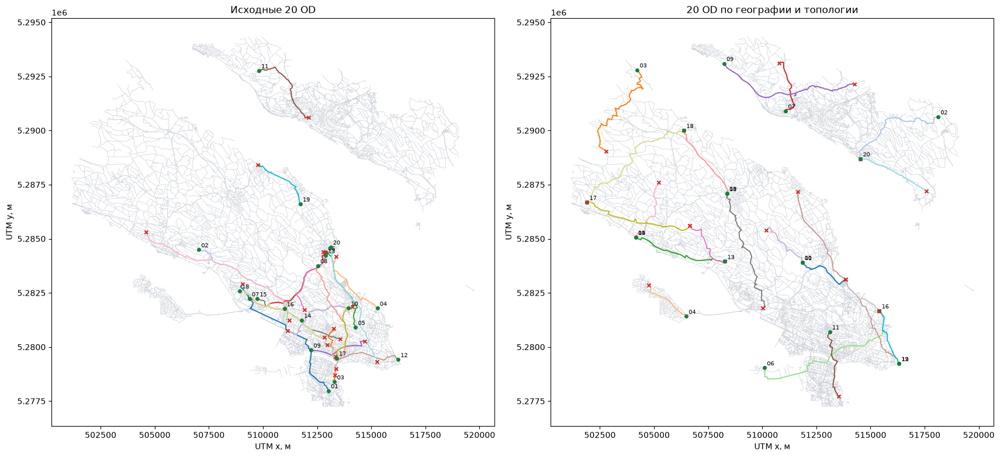

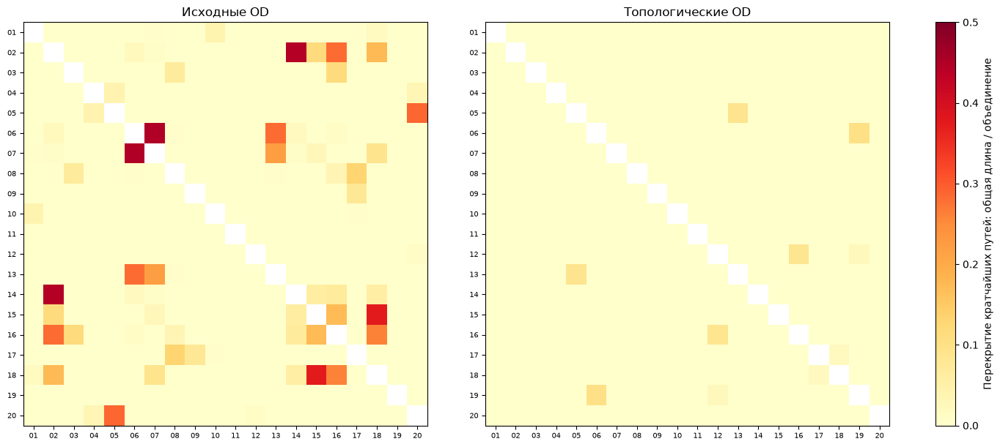

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(17, 10), layout="constrained")
for axis, title, description, shortest in [
    (axes[0], "Исходные 20 OD", current_topology, current_shortest),
    (axes[1], "20 OD по географии и топологии", topology_description, topology_shortest),
]:
    ml_network[ml_surveyed].plot(ax=axis, color="#d1d5db", linewidth=0.35)
    shortest.plot(ax=axis, column="od_id", cmap="tab20", linewidth=1.4)
    for od_id, row in description.iterrows():
        axis.scatter(row.start_x, row.start_y, color="#15803d", s=16, zorder=5)
        axis.scatter(row.end_x, row.end_y, color="#dc2626", marker="x", s=18, zorder=5)
        axis.annotate(od_id[-2:], (row.start_x, row.start_y), xytext=(3, 3), textcoords="offset points", fontsize=7)
    axis.set(title=title, xlabel="UTM x, м", ylabel="UTM y, м")
    axis.set_aspect("equal")
fig.savefig(OD_OUTPUT_DIR / "od_geography.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
for axis, title, shortest in [(axes[0], "Исходные OD", current_shortest), (axes[1], "Топологические OD", topology_shortest)]:
    overlap = route_overlap(shortest, ml_network)
    overlap_values = overlap.to_numpy(copy=True)
    np.fill_diagonal(overlap_values, np.nan)
    im = axis.imshow(overlap_values, vmin=0, vmax=0.5, cmap="YlOrRd")
    axis.set(xticks=range(len(overlap)), yticks=range(len(overlap)),
             xticklabels=[s[-2:] for s in overlap.columns], yticklabels=[s[-2:] for s in overlap.index], title=title)
    axis.tick_params(labelsize=7)
fig.colorbar(im, ax=axes, label="Перекрытие кратчайших путей: общая длина / объединение")
fig.savefig(OD_OUTPUT_DIR / "corridor_overlap.png", dpi=150)
plt.show()


In [22]:
import folium
from matplotlib.colors import to_hex

od_map = folium.Map(tiles="CartoDB positron")
for title, pairs_frame, route_frame, shown in [
    ("Исходные 20 OD", current_pairs, current_shortest, True),
    ("Топологические 20 OD", topology_pairs, topology_shortest, False),
]:
    layer = folium.FeatureGroup(name=title, show=shown)
    lines = route_frame[["od_id", "geometry", "route_length_m"]].to_crs("EPSG:4326").copy()
    lines["color"] = [to_hex(plt.get_cmap("tab20")(i % 20)) for i in range(len(lines))]
    folium.GeoJson(lines, style_function=lambda feature: {
        "color": feature["properties"]["color"], "weight": 4, "opacity": 0.8,
    }, tooltip=folium.GeoJsonTooltip(fields=["od_id", "route_length_m"], aliases=["OD", "Длина, м"])).add_to(layer)
    for pair in pairs_frame.itertuples():
        folium.CircleMarker([pair.start_lat, pair.start_lon], radius=4, color="green",
                            tooltip=f"{pair.od_id}: старт").add_to(layer)
        folium.CircleMarker([pair.end_lat, pair.end_lon], radius=4, color="red",
                            tooltip=f"{pair.od_id}: финиш").add_to(layer)
    layer.add_to(od_map)
bounds = np.array([current_shortest.to_crs("EPSG:4326").total_bounds,
                   topology_shortest.to_crs("EPSG:4326").total_bounds])
od_map.fit_bounds([[bounds[:, 1].min(), bounds[:, 0].min()], [bounds[:, 3].max(), bounds[:, 2].max()]])
folium.LayerControl(collapsed=False).add_to(od_map)
od_map.save(OD_OUTPUT_DIR / "od_map.html")
display(od_map)


D:\PythonProjects\CicleGpx\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


### Все пресеты на обоих наборах OD

Сравниваем 8 стандартных профилей, пользовательские `mine` и `code`, зафиксированный ML и shortest.
Все 40 пар строятся одним пакетным прогоном. Для каждого набора показываем два среза:

- **measured**: популярность только по рёбрам с сопоставленным измерением, при покрытии не ниже 50% у каждого решения.
  Это описательное сравнение набора, не независимый test для ML. Пропуски не считаются нулями.
- **test**: только отложенные участки, при покрытии не ниже 10% у каждого решения.

Внутри каждого среза все показатели считаются на одинаковом пересечении OD для всех моделей,
включая объезд и повороты. Число таких OD показано явно. Топологические OD не подбираются по test-значениям.
Рейтинг популярности нужно читать вместе с объездом: высокий выигрыш ценой большого удлинения не означает
лучшее решение. Пресеты сравниваются как готовые решения с их собственными штрафами поворотов.


In [23]:
od_profiles = {
    **MY_PRESETS,
    "ml_frozen": {
        "label": f"ML α={best_ml_strength:g}", "turns": None, "search": "dijkstra",
        "cost": popularity_cost(ml_network, ml_prediction, strength=best_ml_strength,
                                reference_log=ml_model.reference_log),
    },
}
all_od_pairs = pd.concat([current_pairs, topology_pairs], ignore_index=True)
all_od_routes = build_routes(
    ml_network, ml_nodes, all_od_pairs, od_profiles, cache_dir=OD_OUTPUT_DIR / "all_presets_cache",
)
od_suites = {
    "current": (current_pairs, current_topology),
    "topology": (topology_pairs, topology_description),
}
od_reports, od_detail_frames = [], []
for suite, (suite_pairs, description) in od_suites.items():
    suite_routes = all_od_routes[all_od_routes.od_id.isin(suite_pairs.od_id)]
    for scope, evaluation_mask, coverage in [
        ("measured", ml_known, 50.0), ("test", ml_partition.eq("test") & ml_known, 10.0),
    ]:
        summary, detail = evaluate_od_models(
            suite_routes, ml_network, ml_trips, mask=evaluation_mask, min_coverage_pct=coverage,
        )
        summary["suite"], summary["scope"] = suite, scope
        detail["suite"], detail["scope"] = suite, scope
        od_reports.append(summary.reset_index())
        od_detail_frames.append(detail)
od_model_summary = pd.concat(od_reports, ignore_index=True)
od_model_details = pd.concat(od_detail_frames, ignore_index=True)
od_model_summary["rank_popularity"] = od_model_summary.groupby(["suite", "scope"]).median_log_gain.rank(
    method="min", ascending=False,
)
od_model_summary["median_detour_within_20pct"] = od_model_summary.median_detour_pct.le(20)
od_model_summary["rank_within_20pct"] = od_model_summary.median_log_gain.where(
    od_model_summary.all_od_median_detour_pct.le(MAX_DETOUR_PCT)
).groupby([od_model_summary.suite, od_model_summary.scope]).rank(method="min", ascending=False)
display(od_model_summary[od_model_summary.scope.eq("measured")].set_index(["algorithm", "suite"])[[
    "n_routes", "n_evaluated", "popularity_ratio", "median_detour_pct", "median_turns", "rank_popularity", "rank_within_20pct",
]].sort_index().round(3))
display(od_model_summary[od_model_summary.scope.eq("test")].set_index(["algorithm", "suite"])[[
    "n_evaluated", "popularity_ratio", "median_detour_pct", "all_od_median_detour_pct", "median_coverage_pct", "rank_within_20pct",
]].sort_index().round(3))
od_model_summary.to_csv(OD_OUTPUT_DIR / "all_presets_summary.csv", index=False)
od_model_details.to_csv(OD_OUTPUT_DIR / "all_presets_per_od.csv", index=False)
assert all_od_routes.groupby("algorithm").size().eq(len(all_od_pairs)).all(), "Не все решения построили все OD"


Routes by preset:   0%|          | 0/12 [00:00<?, ?it/s]

Routes by preset:  17%|█▋        | 2/12 [00:00<00:01,  6.58it/s]

Routes by preset:  25%|██▌       | 3/12 [00:00<00:01,  4.65it/s]

Routes by preset:  33%|███▎      | 4/12 [00:00<00:01,  4.02it/s]

Routes by preset:  42%|████▏     | 5/12 [00:01<00:01,  3.80it/s]

...

Routes by preset:  83%|████████▎ | 10/12 [00:02<00:00,  3.50it/s]

Routes by preset: 100%|██████████| 12/12 [00:06<00:00,  1.13s/it]

Routes by preset: 100%|██████████| 12/12 [00:06<00:00,  1.76it/s]

n_routes  n_evaluated  popularity_ratio  \
algorithm  suite                                               
avenues    current         20           20             1.858   
           topology        20           17             3.163   
balanced   current         20           20             3.116   
           topology        20           17             3.163   
bike_infra current         20           20             1.994   
           topology        20           17             3.330   
code       current         20           20             1.100   
           topology        20           17             1.000   
fast       current         20           20             1.523   
           topology        20           17             1.386   
min_turns  current         20           20             1.480   
           topology        20           17             1.588   
mine       current         20           20             2.911   
           topology        20           17             3.163   
ml_frozen  current         20           20             3.969   
           topology        20           17             4.204   
nature     current         20           20             1.798   
           topology        20           17             1.822   
quiet      current         20           20             2.124   
           topology        20           17             1.817   
shortest   current         20           20             1.000   
           topology        20           17             1.000   
smooth     current         20           20             1.596   
           topology        20           17             2.394   

                     median_detour_pct  median_turns  rank_popularity  \
algorithm  suite                                                        
avenues    current               5.421           9.5              6.0   
           topology              3.865           7.0              3.0   
balanced   current               6.453          10.0              2.0   
           topology              3.865           7.0              3.0   
bike_infra current               7.808          11.0              5.0   
           topology              8.480           9.0              2.0   
code       current               4.515          15.0             11.0   
           topology              0.831           8.0             11.0   
fast       current               2.096           9.5              9.0   
           topology              2.289           6.0             10.0   
min_turns  current               7.368           6.0             10.0   
           topology              4.340           4.0              9.0   
mine       current               7.041          10.0              3.0   
           topology              3.865           7.0              3.0   
ml_frozen  current              11.857          10.0              1.0   
           topology             10.229           9.0              1.0   
nature     current               7.941          10.0              7.0   
           topology              7.168           7.0              7.0   
quiet      current               9.353          12.0              4.0   
           topology              4.340           8.0              8.0   
shortest   current               0.000          12.5             12.0   
           topology              0.000           7.0             11.0   
smooth     current               8.465          11.0              8.0   
           topology             10.238           9.0              6.0   

                     rank_within_20pct  
algorithm  suite                        
avenues    current                 6.0  
           topology                3.0  
balanced   current                 2.0  
           topology                3.0  
bike_infra current                 5.0  
           topology                2.0  
code       current                11.0  
           topology               11.0  
fast       current                 9.0  
      

n_evaluated  popularity_ratio  median_detour_pct  \
algorithm  suite                                                        
avenues    current             7             1.600              3.128   
           topology            8             4.238              9.592   
balanced   current             7             1.600              5.756   
           topology            8             4.613              9.592   
bike_infra current             7             1.600              8.698   
           topology            8             3.384             12.035   
code       current             7             1.296              4.510   
           topology            8             2.200              0.803   
fast       current             7             1.474              1.479   
           topology            8             4.238              3.271   
min_turns  current             7             1.693              3.042   
           topology            8             1.867              2.523   
mine       current             7             1.693              6.382   
           topology            8             4.613              9.592   
ml_frozen  current             7             1.600             10.266   
           topology            8             5.055             15.888   
nature     current             7             1.600              5.913   
           topology            8             2.156              5.096   
quiet      current             7             1.365              7.198   
           topology            8             1.702              5.807   
shortest   current             7             1.000              0.000   
           topology            8             1.000              0.000   
smooth     current             7             0.883              8.524   
           topology            8             3.736             10.589   

                     all_od_median_detour_pct  median_coverage_pct  \
algorithm  suite                                                     
avenues    current                      5.421               20.242   
           topology                     4.627               42.636   
balanced   current                      6.453               20.146   
           topology                     4.627               41.970   
bike_infra current                      7.808               18.858   
           topology                     7.725               38.833   
code       current                      4.515               23.656   
           topology                     0.836               37.480   
fast       current                      2.096               23.967   
           topology                     2.443               42.719   
min_turns  current                      7.368               19.517   
           topology                     4.682               37.742   
mine       current                      7.041               20.301   
           topology                     4.627               41.970   
ml_frozen  current                     11.857               18.743   
           topology                     8.494               38.607   
nature     current                      7.941               19.423   
           topology                     6.217               35.155   
quiet      current                      9.353               19.795   
           topology                     5.792               36.432   
shortest   current                      0.000               19.682   
           topology                     0.000               32.004   
smooth     current                      8.465               23.323   
           topology                     9.963               39.047   

                     rank_within_20pct  
algorithm  suite                        
avenues    current                 3.0  
           topology                4.0  
balanced   current                 3.0  
           topology                2.0  
bike_infra current                 3.0  
           top

In [24]:
path_signatures = all_od_routes.assign(signature=all_od_routes.edge_route.map(
    lambda path: tuple(tuple(edge) for edge in path)
)).groupby("od_id").signature.nunique().rename("distinct_paths")
od_pair_reports = []
for suite, (suite_pairs, description) in od_suites.items():
    details = od_model_details[od_model_details.suite.eq(suite) & od_model_details.scope.eq("measured")]
    eligible = details[details.detour_pct.le(20) & details.coverage_pct.ge(50)]
    best_gain = eligible.groupby("od_id").gain.transform("max")
    best_rows = eligible[np.isclose(eligible.gain, best_gain, atol=1e-9, rtol=0)]
    winners = best_rows.groupby("od_id").agg(
        best_under_20pct=("algorithm", lambda names: " / ".join(names)),
        best_log_gain_under_20pct=("gain", "max"), n_tied_best=("algorithm", "nunique"),
    )
    per_od = description.join(path_signatures).join(winners)
    per_od["suite"] = suite
    od_pair_reports.append(per_od.reset_index())
od_pair_effects = pd.concat(od_pair_reports, ignore_index=True)
display(od_pair_effects[["suite", "od_id", "length_km", "length_band", "orientation", "distinct_paths",
                         "best_under_20pct", "n_tied_best", "best_log_gain_under_20pct"]].round(3))
od_pair_effects.to_csv(OD_OUTPUT_DIR / "per_od_distinguishability.csv", index=False)

strata = od_model_details[od_model_details.scope.eq("measured") & od_model_details.included].merge(
    od_pair_effects[["od_id", "length_band", "orientation"]], on="od_id", validate="many_to_one",
)
stratified = strata.groupby(["suite", "length_band", "algorithm"]).agg(
    n_od=("od_id", "nunique"), median_log_gain=("gain", "median"), median_detour_pct=("detour_pct", "median"),
)
display(stratified.round(3))
stratified.to_csv(OD_OUTPUT_DIR / "presets_by_length.csv")
by_orientation = strata.groupby(["suite", "orientation", "algorithm"]).agg(
    n_od=("od_id", "nunique"), median_log_gain=("gain", "median"), median_detour_pct=("detour_pct", "median"),
)
by_orientation.to_csv(OD_OUTPUT_DIR / "presets_by_orientation.csv")


,suite,od_id,length_km,length_band,orientation,distinct_paths,best_under_20pct,n_tied_best,best_log_gain_under_20pct
0,current,DE-01,7.818,6–10 km,NW–SE,11,ml_frozen,1.0,1.781
1,current,DE-02,8.110,6–10 km,NW–SE,8,fast,1.0,2.493
2,current,DE-03,3.085,3–6 km,N–S,10,fast,1.0,2.208
3,current,DE-04,3.592,3–6 km,NW–SE,4,balanced / fast / min_turns / avenues / quiet ...,9.0,0.164
4,current,DE-05,4.448,3–6 km,NW–SE,10,bike_infra / ml_frozen,2.0,1.630
5,current,DE-06,4.228,3–6 km,NE–SW,10,ml_frozen,1.0,0.644
6,current,DE-07,5.260,3–6 km,NE–SW,11,nature,1.0,0.631
7,current,DE-08,5.856,3–6 km,N–S,12,mine,1.0,1.055
8,current,DE-09,2.944,1.5–3 km,E–W,7,nature,1.0,0.542
9,current,DE-10,3.868,3–6 km,E–W,10,avenues,1.0,0.738


n_od  median_log_gain  median_detour_pct
suite    length_band algorithm                                           
current  1.5–3 km    avenues        1            0.081              1.368
                     balanced       1            0.081              1.368
                     bike_infra     1            0.081              1.368
                     code           1           -0.933             13.416
                     fast           1            0.081              1.368
...                               ...              ...                ...
topology 6–10 km     ml_frozen      5            0.817              6.323
                     nature         5            0.600             12.404
                     quiet          5            0.597             10.940
                     shortest       5            0.000              0.000
                     smooth         5            0.720             10.238

[72 rows x 3 columns]

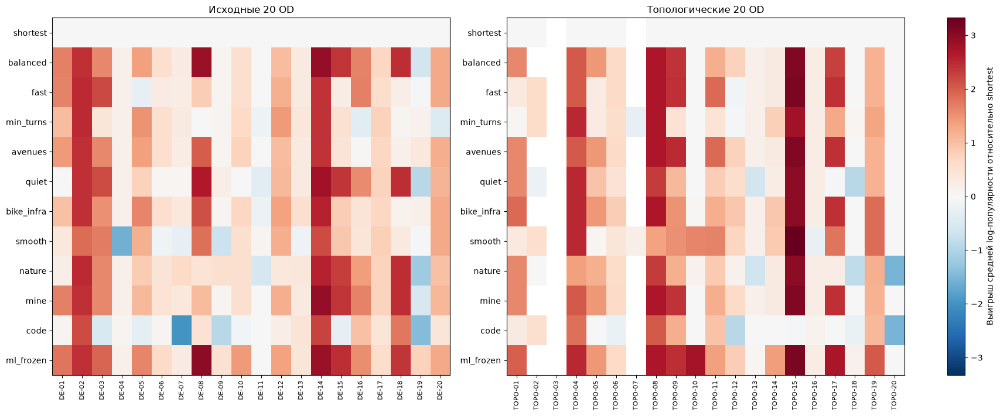

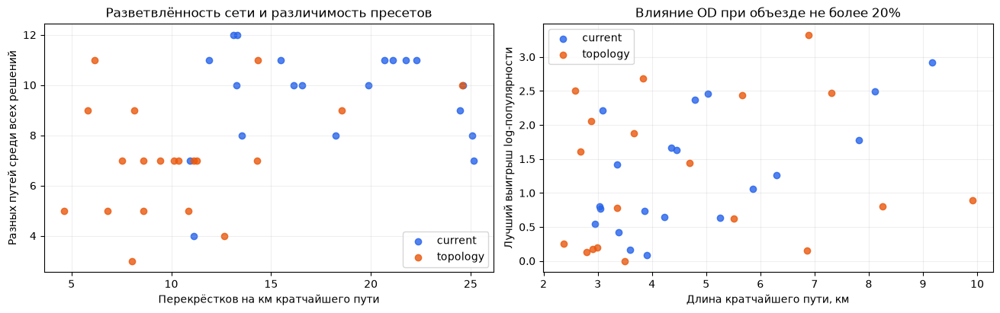

In [25]:
od_model_order = ["shortest", *od_profiles]
matrices = []
for suite in ["current", "topology"]:
    frame = od_model_details[od_model_details.suite.eq(suite) & od_model_details.scope.eq("measured")]
    matrix = frame.pivot(index="algorithm", columns="od_id", values="gain").reindex(od_model_order)
    coverage = frame.pivot(index="algorithm", columns="od_id", values="coverage_pct").reindex(od_model_order)
    matrices.append(matrix.where(coverage.ge(50)))
bound = max(np.nanmax(np.abs(m.to_numpy())) for m in matrices)
fig, axes = plt.subplots(1, 2, figsize=(17, 7), layout="constrained")
for axis, title, matrix in zip(axes, ["Исходные 20 OD", "Топологические 20 OD"], matrices):
    im = axis.imshow(matrix, aspect="auto", cmap="RdBu_r", vmin=-bound, vmax=bound)
    axis.set(xticks=range(len(matrix.columns)), yticks=range(len(matrix.index)),
             xticklabels=matrix.columns, yticklabels=matrix.index, title=title)
    axis.tick_params(axis="x", rotation=90, labelsize=8)
fig.colorbar(im, ax=axes, label="Выигрыш средней log-популярности относительно shortest")
fig.savefig(OD_OUTPUT_DIR / "all_presets_by_od.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
for suite, color in [("current", "#2563eb"), ("topology", "#ea580c")]:
    rows = od_pair_effects[od_pair_effects.suite.eq(suite)]
    axes[0].scatter(rows.junctions_per_km, rows.distinct_paths, color=color, label=suite, alpha=0.8)
    axes[1].scatter(rows.length_km, rows.best_log_gain_under_20pct, color=color, label=suite, alpha=0.8)
axes[0].set(xlabel="Перекрёстков на км кратчайшего пути", ylabel="Разных путей среди всех решений",
            title="Разветвлённость сети и различимость пресетов")
axes[1].set(xlabel="Длина кратчайшего пути, км", ylabel="Лучший выигрыш log-популярности",
            title="Влияние OD при объезде не более 20%")
for axis in axes:
    axis.legend(); axis.grid(alpha=0.2)
fig.savefig(OD_OUTPUT_DIR / "topology_and_model_effect.png", dpi=160)
plt.show()


In [26]:
from IPython.display import Markdown

survey_report = od_model_summary[od_model_summary.scope.eq("measured")]
comparison = survey_report.pivot(index="algorithm", columns="suite",
                                values=["popularity_ratio", "median_detour_pct", "rank_popularity"])
rows = ["| Решение | Популярность: исходные | Популярность: топология | Объезд: исходные | Объезд: топология |",
        "|---|---:|---:|---:|---:|"]
for model in od_model_order:
    row = comparison.loc[model]
    rows.append(f"| {model} | ×{row[('popularity_ratio', 'current')]:.2f} | ×{row[('popularity_ratio', 'topology')]:.2f} | "
                f"{row[('median_detour_pct', 'current')]:.1f}% | {row[('median_detour_pct', 'topology')]:.1f}% |")
test_sizes = od_model_summary[od_model_summary.scope.eq("test")].groupby("suite").n_evaluated.first()
summary_text = (
    f"**Влияние выбора OD на все решения.** Исходные пары имеют медиану "
    f"{current_topology.junctions_per_km.median():.1f} перекрёстка на км; диагностические — "
    f"{topology_description.junctions_per_km.median():.1f}. Медианное число разных путей среди решений: "
    f"{od_pair_effects[od_pair_effects.suite.eq('current')].distinct_paths.median():g} и "
    f"{od_pair_effects[od_pair_effects.suite.eq('topology')].distinct_paths.median():g}. "
    "Пространственное выравнивание даёт больше веса разреженной сети, поэтому тоже меняет условия задачи.\n\n"
    + "\n".join(rows) +
    f"\n\nЭто описательная оценка только по улицам с известным измерением. Для независимого test при сравнении "
    f"всех решений остаётся {test_sizes['current']} общих OD в исходном наборе и {test_sizes['topology']} "
    "в диагностическом; эта таблица находится выше. Значения могут отличаться от сравнения только ML "
    "и shortest, где пересечение OD шире.\n\n"
    "**Как использовать:** сохранять оба фиксированных набора, читать результаты по длинам, направлениям "
    "и разветвлённости, отдельно проверять лимит объезда. OD выбраны без поездок и результатов пресетов, "
    "поэтому различия в таблице показывают чувствительность к условиям маршрута. "
    "Пропуски теперь исключены из обучения и метрик; значения до этого исправления не являются сопоставимым эталоном. Ни один такой диагностический набор сам по себе не оценивает распределение реального спроса."
)
display(Markdown(summary_text))
_ = (OD_OUTPUT_DIR / "analysis.md").write_text(summary_text, encoding="utf-8")


**Влияние выбора OD на все решения.** Исходные пары имеют медиану 17.4 перекрёстка на км; диагностические — 9.8. Медианное число разных путей среди решений: 10 и 7. Пространственное выравнивание даёт больше веса разреженной сети, поэтому тоже меняет условия задачи.

| Решение | Популярность: исходные | Популярность: топология | Объезд: исходные | Объезд: топология |
|---|---:|---:|---:|---:|
| shortest | ×1.00 | ×1.00 | 0.0% | 0.0% |
| balanced | ×3.12 | ×3.16 | 6.5% | 3.9% |
| fast | ×1.52 | ×1.39 | 2.1% | 2.3% |
| min_turns | ×1.48 | ×1.59 | 7.4% | 4.3% |
| avenues | ×1.86 | ×3.16 | 5.4% | 3.9% |
| quiet | ×2.12 | ×1.82 | 9.4% | 4.3% |
| bike_infra | ×1.99 | ×3.33 | 7.8% | 8.5% |
| smooth | ×1.60 | ×2.39 | 8.5% | 10.2% |
| nature | ×1.80 | ×1.82 | 7.9% | 7.2% |
| mine | ×2.91 | ×3.16 | 7.0% | 3.9% |
| code | ×1.10 | ×1.00 | 4.5% | 0.8% |
| ml_frozen | ×3.97 | ×4.20 | 11.9% | 10.2% |

Это описательная оценка только по улицам с известным измерением. Для независимого test при сравнении всех решений остаётся 7 общих OD в исходном наборе и 8 в диагностическом; эта таблица находится выше. Значения могут отличаться от сравнения только ML и shortest, где пересечение OD шире.

**Как использовать:** сохранять оба фиксированных набора, читать результаты по длинам, направлениям и разветвлённости, отдельно проверять лимит объезда. OD выбраны без поездок и результатов пресетов, поэтому различия в таблице показывают чувствительность к условиям маршрута. Пропуски теперь исключены из обучения и метрик; значения до этого исправления не являются сопоставимым эталоном. Ни один такой диагностический набор сам по себе не оценивает распределение реального спроса.